# 02 | Financial Figure Extraction Evaluation (FinanceBench)

Offline regex extractor over the 150 open-source FinanceBench questions. The extractor sees the question and the gold evidence passage, never the gold answer. It is a non-LLM baseline; set `MISTRAL_API_KEY` to evaluate Mistral with the same scoring.

`answer_recoverability_pct` is a separate oracle check: the share of questions whose gold figure appears verbatim in the evidence. It uses the answer key, so it is an upper bound for any extractor, not an accuracy.

In [1]:
import sys, os
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

from src.paths import RAW, PROCESSED, RESULTS
from src import setup_data

RESULTS.mkdir(exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)
if not setup_data.data_present():
    setup_data.main()

/usr/local/lib/python3.12/dist-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.4.0.post2)/charset_normalizer (3.4.6) doesn't match a supported version!
  warnings.warn(


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from src.llm_eval import load_financebench, evaluate_extraction, summarize, MISTRAL_MODEL

records = load_financebench(RAW / "financebench" / "financebench_open_source.jsonl")
API_KEY = os.environ.get("MISTRAL_API_KEY")
print(f"Loaded {len(records)} FinanceBench QA pairs")
print(f"Mode: MISTRAL ({MISTRAL_MODEL})" if API_KEY else "Mode: OFFLINE REGEX EXTRACTOR (no LLM API required)")
df_llm = evaluate_extraction(records, api_key=API_KEY)

Loaded 150 FinanceBench QA pairs
Mode: OFFLINE REGEX EXTRACTOR (no LLM API required)


Evaluating:   0%|          | 0/150 [00:00<?, ?it/s]

In [3]:
s = summarize(df_llm)
label = {"Type1_unit_hallucination": "Type1 Unit Hallucination",
         "Type2_period_mismatch": "Type2 Period Mismatch",
         "Type3_table_misread": "Type3 Table Misread"}
print(f"Exact Match: {s['exact_match_pct']}%")
print(f"Numeric Match (significant digits, scale-agnostic): {s['numeric_match_pct']}%")
print(f"Precision (correct / attempted): {s['precision_pct']}%")
print(f"Recall (correct / all questions): {s['recall_pct']}%")
print(f"Answer recoverability (gold figure present in evidence, oracle): {s['answer_recoverability_pct']}%")
print("\nError Breakdown (share of wrong answers):")
for k in label:
    print(f"  {label[k]}: {s['error_breakdown_pct'].get(k, 0.0)}%")
print("\nBy question type:")
print(df_llm.groupby("question_type")[["exact_match", "gold_in_evidence"]].mean().mul(100).round(1).to_string())
print("\nReference: FinanceBench paper (Islam et al., 2023), GPT-4-Turbo with a shared vector store about 19% correct.")

Exact Match: 6.7%
Numeric Match (significant digits, scale-agnostic): 6.7%
Precision (correct / attempted): 6.8%
Recall (correct / all questions): 6.7%
Answer recoverability (gold figure present in evidence, oracle): 25.3%

Error Breakdown (share of wrong answers):
  Type1 Unit Hallucination: 0.7%
  Type2 Period Mismatch: 0.0%
  Type3 Table Misread: 99.3%

By question type:
                   exact_match  gold_in_evidence
question_type                                   
domain-relevant           12.0              30.0
metrics-generated          0.0              14.0
novel-generated            8.0              32.0

Reference: FinanceBench paper (Islam et al., 2023), GPT-4-Turbo with a shared vector store about 19% correct.


 Many FinanceBench answers need arithmetic (ratios, year-over-year changes) or are written sentences, so a span extractor cannot get them right; the metrics-generated slice shows this most clearly. The error taxonomy is a rule-based heuristic and Type3 is the catch-all.

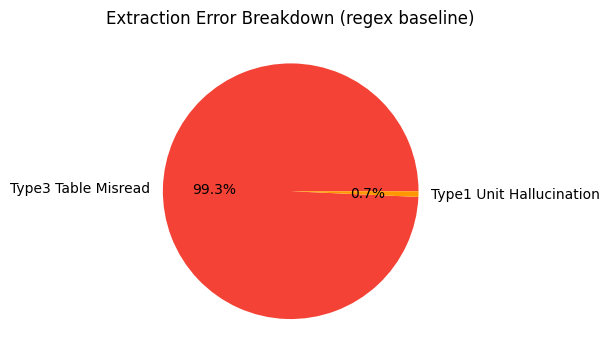

In [4]:
errors = df_llm[~df_llm["error_type"].isin(["correct", "api_error"])]["error_type"].map(label)
fig, ax = plt.subplots(figsize=(6, 6))
if len(errors):
    errors.value_counts().plot(kind="pie", autopct="%1.1f%%", ax=ax, colors=["#F44336", "#FF9800", "#2196F3"])
ax.set_title("Extraction Error Breakdown (" + ("regex baseline" if s["mode"] == "regex" else MISTRAL_MODEL) + ")")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(RESULTS / "llm_error_breakdown.png", dpi=150)
plt.show()

In [5]:
df_llm.to_csv(RESULTS / "llm_accuracy_scorecard.csv", index=False)
summary = {k: v for k, v in s.items() if k != "error_breakdown_pct"}
summary.update({f"err_{k}": v for k, v in s["error_breakdown_pct"].items()})
pd.DataFrame([summary]).to_csv(RESULTS / "llm_eval_summary.csv", index=False)
print("Saved llm_accuracy_scorecard.csv and llm_eval_summary.csv")

Saved llm_accuracy_scorecard.csv and llm_eval_summary.csv
